# 02: Statistical Exploratory Data Analysis
***
**Author:** Zain Zabidi
**Date:** February 2026

**Objective:** To perform a rigorous statistical analysis of the processed Census data, identifying correlations, testing geographical hypotheses, and detecting spatial clustering of housing stress across Western Australia.

## 1. Setup and Data Loading
In this section, we initialise our environment and load the datasets created in the previous notebook. We primarily use the GeoPackage (`.gpkg`) file because it contains both our engineered numerical features and the spatial geometries required for our mapping and autocorrelation tests.

### 1.1 Import Libraries
We begin by importing the necessary libraries for our analysis. This includes `scipy.stats` for our hypothesis testing and `seaborn/matplotlib` for visualising our data distributions.

In [1]:
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import os

# Set plotting style for consistency
plt.style.use('ggplot')
sns.set_palette("viridis")

# Path configuration
PROCESSED_DATA_PATH = '../data/processed/'

### 1.2 Load Processed Data
Next, we load the spatial dataset we exported at the end of Notebook 01. Loading the `GeoPackage` into a GeoDataFrame allows us to access all 600+ census variables alongside their corresponding geographical boundaries for Western Australia.

In [2]:
# Load the spatial dataset
geo_path = os.path.join(PROCESSED_DATA_PATH, 'wa_census_spatial_2021.gpkg')
df = gpd.read_file(geo_path)

# Quick check of the dataframe structure to ensure all records imported correctly
print(f"Dataset loaded with {df.shape[0]} suburbs and {df.shape[1]} columns.")
display(df[['SAL_NAME21', 'avg_weekly_income', 'housing_stress_index']].head())

Dataset loaded with 1699 suburbs and 659 columns.


,SAL_NAME21,avg_weekly_income,housing_stress_index
0,Abba River,2946.107143,23.692464
1,Abbey,1830.418860,22.783521
2,Acton Park (WA),1320.258621,35.945114
3,Adamsvale,4800.000000,0.000000
4,Ajana,449.500000,0.000000


## 2. Univariate Analysis

In this section, we examine the distribution of our primary variables. Before we can test how different variables relate to each other, we need to understand the "shape" of our data. We will look for skewness, outliers, and the general spread of housing stress across the state.

### 2.1 Distribution of Housing Stress

We start by visualising the `housing_stress_index`. This index represents the percentage of household income spent on rent or mortgage repayments. By using a histogram and a boxplot together, we can identify the central tendency and see how many suburbs are experiencing extreme levels of financial pressure.

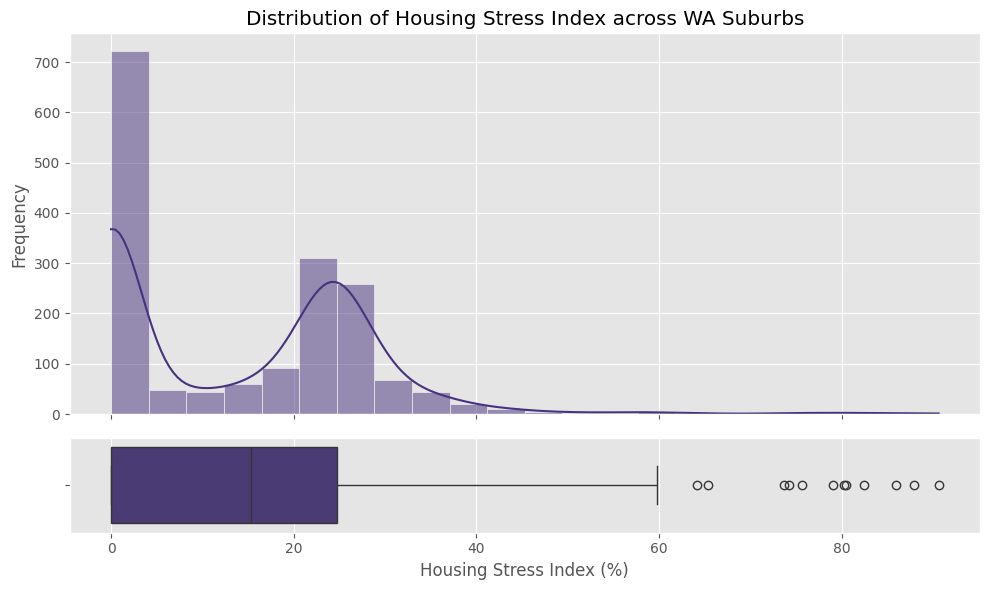

count    1699.000000
mean       14.092720
std        14.212830
min         0.000000
25%         0.000000
50%        15.310382
75%        24.714447
max        90.591874
Name: housing_stress_index, dtype: float64


In [3]:
# Create a figure with two subplots: a histogram and a boxplot
fig, (ax_hist, ax_box) = plt.subplots(2, sharex=True, gridspec_kw={"height_ratios": (.8, .2)}, figsize=(10, 6))

# Plot the histogram to show the frequency of stress levels
sns.histplot(data=df, x='housing_stress_index', kde=True, ax=ax_hist)
ax_hist.set_title('Distribution of Housing Stress Index across WA Suburbs')
ax_hist.set_ylabel('Frequency')

# Plot the boxplot to highlight outliers
sns.boxplot(data=df, x='housing_stress_index', ax=ax_box)
ax_box.set_xlabel('Housing Stress Index (%)')

plt.tight_layout()
plt.show()

# Calculate descriptive statistics for a numerical summary
print(df['housing_stress_index'].describe())

### 2.2 Observations on Housing Stress

Based on the visual and numerical summary, we can make the following observations:

* **Bimodal Distribution:** The data shows two distinct peaks. The peak at `0%` likely represents suburbs where households own their homes outright or data is suppressed. The second peak, around `20-25%`, represents the typical experience for active renters and mortgage holders.
* **Significant Outliers:** The boxplot identifies several `extreme outliers` with stress levels exceeding `60%`, reaching a maximum of `90.6%`. These suburbs are under intense financial pressure compared to the state average.
* **Skewness & Central Tendency:** While the `mean` is `14.09%`, the `median` of `15.31%` shows that once we move past the zero-value suburbs, the distribution leans toward the higher end of the scale.

### 2.3 Distribution of Income and Mining Concentration

To understand the economic drivers behind housing stress, we examine the spread of wealth and industrial specialisation. `Average Weekly Income` tells us about the financial capacity of a suburb, while the `Mining Concentration Ratio` identifies areas heavily dependent on the resources sector. 

Observing these distributions helps us decide if we need to apply any transformations (like log scaling) before moving into regression modelling.

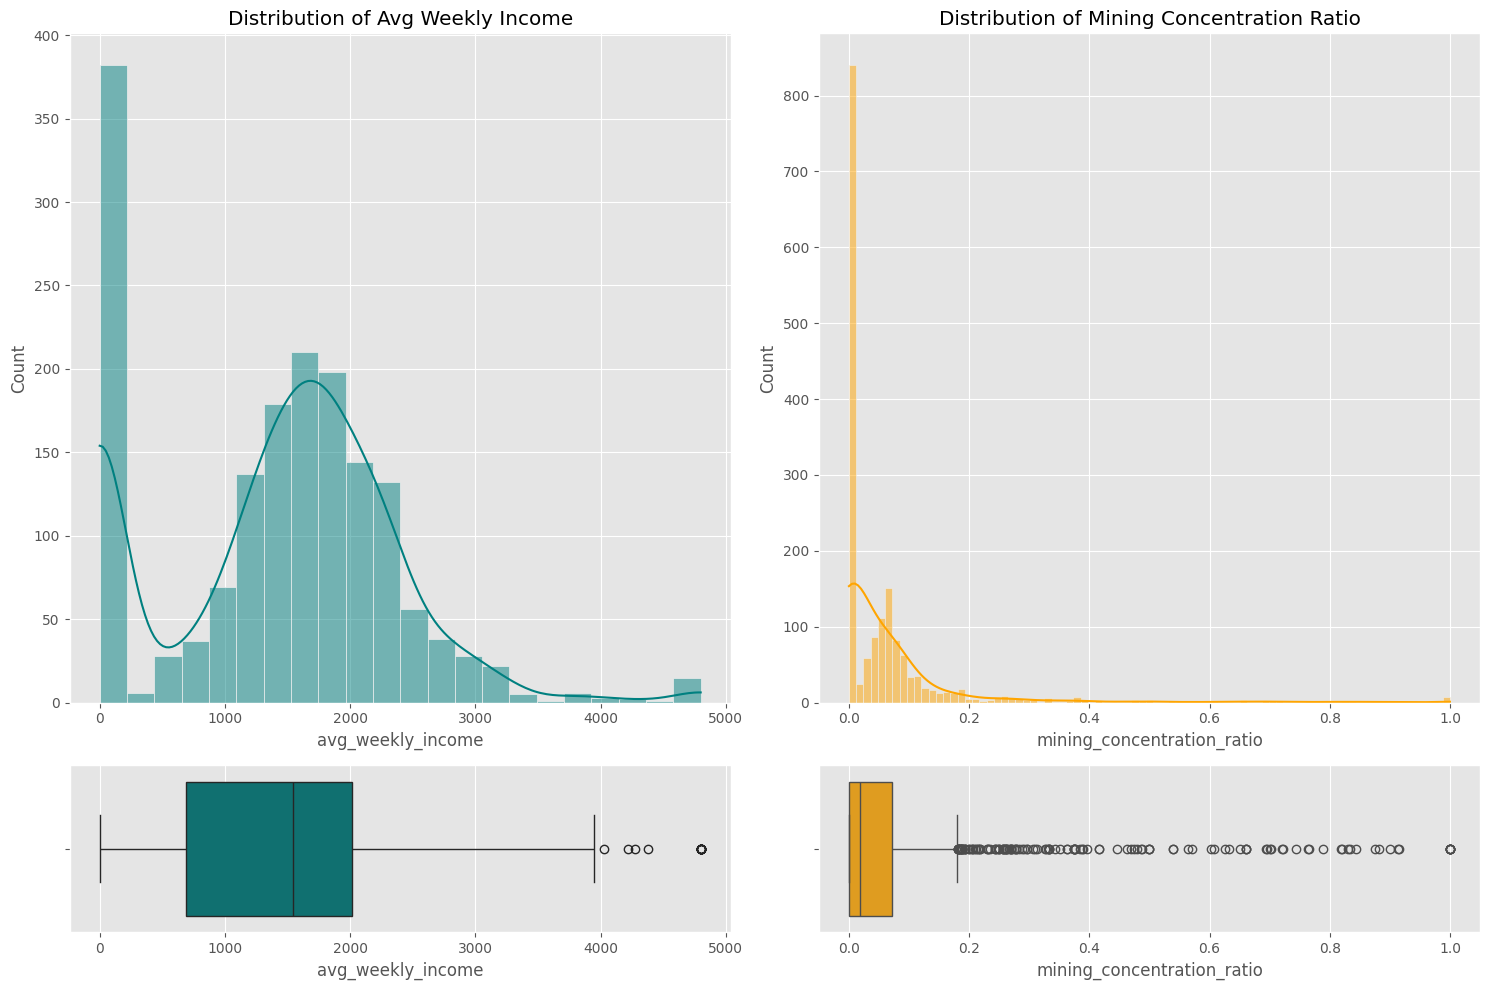

,avg_weekly_income,mining_concentration_ratio
count,1699.000000,1699.000000
mean,1399.908593,0.065469
std,963.589463,0.134410
min,0.000000,0.000000
25%,689.325000,0.000000
50%,1540.831568,0.018546
75%,2014.703792,0.072401
max,4800.000000,1.000000


In [4]:
# Set up grid for two sets of plots
fig, axes = plt.subplots(2, 2, figsize=(15, 10), gridspec_kw={"height_ratios": (.8, .2)})

# Plot 1: Average Weekly Income
sns.histplot(data=df, x='avg_weekly_income', kde=True, ax=axes[0, 0], color='teal')
axes[0, 0].set_title('Distribution of Avg Weekly Income')
sns.boxplot(data=df, x='avg_weekly_income', ax=axes[1, 0], color='teal')

# Plot 2: Mining Concentration Ratio
sns.histplot(data=df, x='mining_concentration_ratio', kde=True, ax=axes[0, 1], color='orange')
axes[0, 1].set_title('Distribution of Mining Concentration Ratio')
sns.boxplot(data=df, x='mining_concentration_ratio', ax=axes[1, 1], color='orange')

plt.tight_layout()
plt.show()

# Display summary statistics for both
display(df[['avg_weekly_income', 'mining_concentration_ratio']].describe())

### 2.4 Observations on Economic Drivers

Based on the visual and numerical summary, we can refine our insights:

* **Bimodal Income:** The `avg_weekly_income` follows a bimodal pattern similar to housing stress. Beyond the initial spike at `$0`, the data is normally distributed around a median of `$1,540`, with "prestige" outliers reaching up to `$4,800`.
* **Extreme Mining Specialisation:** The `mining_concentration_ratio` is intensely right-skewed. While the `median` suburb has less than `2%` mining employment, the outliers reach a staggering `100% (1.0)`. This highlights the extreme industrial specialisation in certain WA regions.
* **Structural Zeros:** The consistent presence of `0` values across income, mining, and stress confirms that our dataset includes non-residential or industrially-zoned areas (like `Adamsvale` or `Ajana`) which we may need to handle before regression modelling.